<a href="https://colab.research.google.com/github/Dhanshreeshende/Optimization_Techinique/blob/main/MiniProject10_05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

       FOODRESCUE OPTIMIZATION RESULTS

OPTIMIZED DISTRIBUTION PLAN:
       Donor         NGO Food Type  Quantity  Distance (km)  Transport Cost (Rs)
Restaurant A   NGO North     Meals        30              4                 60.0
    Bakery B NGO Central    Bakery        25              3                 37.5
     Hotel C   NGO South     Meals        35              2                 35.0

PERFORMANCE METRICS
-----------------------------------
Total food supply: 120 portions
Total NGO demand: 90 portions
Food distributed: 90 portions
Undistributed food: 30 portions
Unmet NGO demand: 0 portions
Demand fulfillment: 100.0 %
Distribution rate: 75.0 %
Transport cost: Rs 132.5
Optimization status: SUCCESS
Objective value: 1332.5


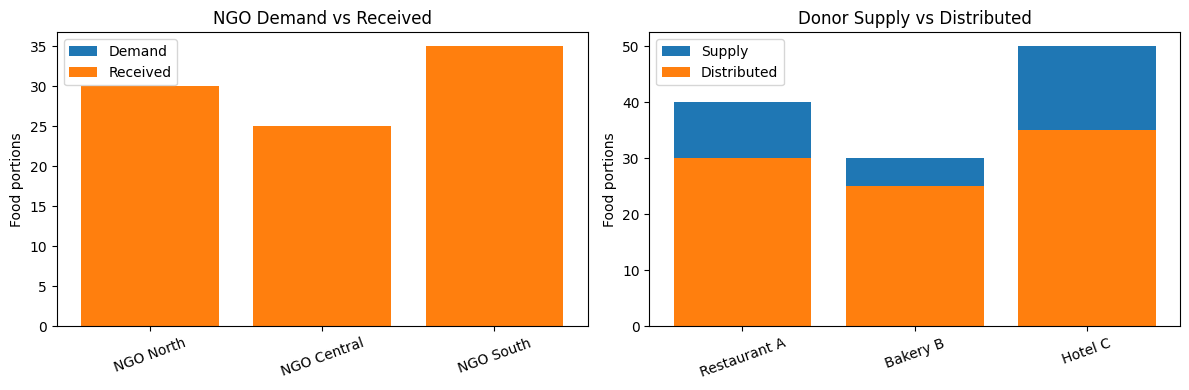


Results saved to foodrescue_results.csv


In [22]:
# FOODRESCUE: Food Rescue and Redistribution Optimizer

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.sparse import lil_matrix

# 1. FOOD DONORS
donors = pd.DataFrame({
    "Donor": ["Restaurant A", "Bakery B", "Hotel C"],
    "Supply": [40, 30, 50],
    "Type": ["Meals", "Bakery", "Meals"],
    "Expiry": [3, 8, 2]
})

# 2. NGO REQUIREMENTS
ngos = pd.DataFrame({
    "NGO": ["NGO North", "NGO Central", "NGO South"],
    "Demand": [30, 25, 35],
    "Type": ["Meals", "Bakery", "Meals"]
})

# 3. DISTANCES IN KM (donors x NGOs)
distance = np.array([
    [4, 7, 6],
    [8, 3, 5],
    [5, 9, 2]
])

# Assume average vehicle speed of 25 km/hour
travel_time = distance / 25

D = len(donors)
N = len(ngos)
pairs = [(i, j) for i in range(D) for j in range(N)]
m = len(pairs)

# 4. COST FUNCTION
transport_cost = []
for i, j in pairs:
    compatible = donors.loc[i, "Type"] == ngos.loc[j, "Type"]
    can_arrive = travel_time[i, j] <= donors.loc[i, "Expiry"]
    transport_cost.append(
        distance[i, j] * 0.5 if compatible and can_arrive else 0
    )

# Variables: allocation (m), leftover food (D), unmet demand (N)
total_vars = m + D + N

# Large costs discourage waste and unmet demand
cost = np.array(
    transport_cost + [40] * D + [60] * N,
    dtype=float
)

# 5. CONSTRAINT MATRIX
A = lil_matrix((D + N, total_vars), dtype=float)

# Donor supply constraints
for i in range(D):
    for k, (di, nj) in enumerate(pairs):
        if di == i:
            A[i, k] = 1
    A[i, m + i] = 1

# NGO demand constraints
for j in range(N):
    for k, (di, nj) in enumerate(pairs):
        if nj == j:
            A[D + j, k] = 1
    A[D + j, m + D + j] = 1

rhs = np.concatenate([
    donors["Supply"].to_numpy(),
    ngos["Demand"].to_numpy()
])

# Prevent incompatible or infeasible allocations
upper_bounds = np.full(total_vars, np.inf)
for k, (i, j) in enumerate(pairs):
    compatible = donors.loc[i, "Type"] == ngos.loc[j, "Type"]
    can_arrive = travel_time[i, j] <= donors.loc[i, "Expiry"]
    if not (compatible and can_arrive):
        upper_bounds[k] = 0

# 6. RUN INTEGER LINEAR PROGRAMMING
result = milp(
    c=cost,
    integrality=np.ones(total_vars),
    bounds=Bounds(np.zeros(total_vars), upper_bounds),
    constraints=LinearConstraint(A.tocsr(), rhs, rhs)
)

# 7. DISPLAY RESULTS
if result.success:
    allocations = []

    for k, (i, j) in enumerate(pairs):
        qty = int(round(result.x[k]))

        if qty > 0:
            allocations.append({
                "Donor": donors.loc[i, "Donor"],
                "NGO": ngos.loc[j, "NGO"],
                "Food Type": donors.loc[i, "Type"],
                "Quantity": qty,
                "Distance (km)": distance[i, j],
                "Transport Cost (Rs)": round(
                    qty * distance[i, j] * 0.5, 2
                )
            })

    allocation_df = pd.DataFrame(allocations)

    print("=" * 55)
    print("       FOODRESCUE OPTIMIZATION RESULTS")
    print("=" * 55)

    if not allocation_df.empty:
        print("\nOPTIMIZED DISTRIBUTION PLAN:")
        print(allocation_df.to_string(index=False))
    else:
        print("No food can be allocated under the current constraints.")

    distributed = int(round(sum(result.x[:m])))
    leftover = int(round(sum(result.x[m:m + D])))
    unmet = int(round(sum(result.x[m + D:])))

    supply = int(donors["Supply"].sum())
    demand = int(ngos["Demand"].sum())
    cost_total = sum(
        row["Transport Cost (Rs)"] for row in allocations
    )

    print("\nPERFORMANCE METRICS")
    print("-" * 35)
    print("Total food supply:", supply, "portions")
    print("Total NGO demand:", demand, "portions")
    print("Food distributed:", distributed, "portions")
    print("Undistributed food:", leftover, "portions")
    print("Unmet NGO demand:", unmet, "portions")
    print("Demand fulfillment:",
          round(100 * (demand - unmet) / demand, 2), "%")
    print("Distribution rate:",
          round(100 * distributed / supply, 2), "%")
    print("Transport cost: Rs", round(cost_total, 2))
    print("Optimization status: SUCCESS")
    print("Objective value:", round(result.fun, 2))

    # 8. VISUALIZE RESULTS
    received = [
        sum(int(round(result.x[k]))
            for k, (i, jj) in enumerate(pairs) if jj == j)
        for j in range(N)
    ]

    sent = [
        sum(int(round(result.x[k]))
            for k, (ii, j) in enumerate(pairs) if ii == i)
        for i in range(D)
    ]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].bar(ngos["NGO"], ngos["Demand"], label="Demand")
    axes[0].bar(ngos["NGO"], received, label="Received")
    axes[0].set_title("NGO Demand vs Received")
    axes[0].set_ylabel("Food portions")
    axes[0].tick_params(axis="x", rotation=20)
    axes[0].legend()

    axes[1].bar(donors["Donor"], donors["Supply"], label="Supply")
    axes[1].bar(donors["Donor"], sent, label="Distributed")
    axes[1].set_title("Donor Supply vs Distributed")
    axes[1].set_ylabel("Food portions")
    axes[1].tick_params(axis="x", rotation=20)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    # 9. SAVE RESULTS
    allocation_df.to_csv("foodrescue_results.csv", index=False)
    print("\nResults saved to foodrescue_results.csv")

else:
    print("Optimization failed:", result.message)